# Project 2: Supervised Learning (Fraud Detection Pipeline)
**DecodeLabs | Data Science | Batch 2026**

**Goal:** build and tune classification models that identify fraudulent transactions in a highly imbalanced dataset, without letting any information leak from the test data into training.

**Key requirements (from the project brief)**
1. Handle class imbalance with **SMOTE**
2. Train multiple algorithms (**Logistic Regression** and **Random Forest**) with scikit-learn
3. Discard accuracy and evaluate with **Precision, Recall and ROC-AUC**

**How the notebook is organised**

| Module | What happens here | Brief concept |
|---|---|---|
| 1 | Load, clean and explore the data | Why accuracy fails; how imbalanced the data is |
| 2 | Stratified split, baseline model, SMOTE demonstration | "Never apply SMOTE before the split" |
| 3 | Leak-free pipelines and GridSearchCV tuning | `imblearn` Pipeline, cross-validation, hyperparameters |
| 4 | Final evaluation on the untouched test set | Precision, Recall, F1, ROC-AUC, confusion matrix |

**Assumptions**
- **A1.** The data is the *Credit Card Fraud Detection* dataset from Kaggle (284,807 transactions). `Class = 1` means fraud and `Class = 0` means legitimate. `V1` to `V28` are anonymised components, and `Time` and `Amount` are the only original columns.
- **A2.** Exact duplicate rows are removed **before** the split, so an identical transaction cannot sit in both the training and test sets.
- **A3.** To keep run time reasonable, the hyperparameter search runs on a stratified sample of the **training set only** (`TUNE_SAMPLE_SIZE`). The winning settings are then used to retrain each model on the **full** training set. The test set is never involved in tuning.

*Run the notebook top to bottom (Kernel → Restart & Run All). Place `creditcard.csv` in the `data/` folder first.*

## Module 1: Load, clean and explore

In [1]:
import os
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

# imblearn's Pipeline (not sklearn's) is required because SMOTE changes the number of rows
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pd.set_option("display.max_columns", None)
RANDOM_SEED = 42
DATA_PATH = "data/creditcard.csv"      # the data/ folder sits next to this notebook
TUNE_SAMPLE_SIZE = 100_000             # rows of the training set used for the hyperparameter search (None = all)

In [2]:
raw_data = pd.read_csv(DATA_PATH)      # untouched reference copy
df = raw_data.copy()                   # all changes happen on this copy
print("Shape:", raw_data.shape)
raw_data.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Profile of the raw data (the "before" evidence)
raw_data.info()
print("\nMissing values (total):", int(raw_data.isnull().sum().sum()))
print("Duplicate rows:", int(raw_data.duplicated().sum()))
print("\nClass counts:")
print(raw_data["Class"].value_counts())
print(f"\nFraud share: {raw_data['Class'].mean():.4%}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

### 1.1 Cleaning
The checks below confirm the data is usable, and the duplicate removal follows assumption A2.
- **Missing values:** none are expected, but they are checked.
- **Duplicates:** exact duplicate rows are dropped. If the same transaction appeared in both train and test, the test score would be inflated, which is a quiet form of leakage.
- **Sanity checks:** `Class` must be 0 or 1, and `Time` and `Amount` cannot be negative.

In [4]:
n_dupes = int(df.duplicated().sum())
fraud_before = int(df["Class"].sum())
df = df.drop_duplicates().reset_index(drop=True)

assert df.isnull().sum().sum() == 0, "Missing values found"
assert set(df["Class"].unique()) <= {0, 1}, "Class has values other than 0/1"
assert (df["Amount"] >= 0).all() and (df["Time"] >= 0).all(), "Negative Time or Amount"
assert df.duplicated().sum() == 0

print(f"Duplicate rows removed: {n_dupes}")
print(f"Rows before / after:    {len(raw_data):,} / {len(df):,}")
print(f"Fraud cases before / after: {fraud_before} / {int(df['Class'].sum())}")
print(f"Fraud share after cleaning: {df['Class'].mean():.4%}")

Duplicate rows removed: 1081
Rows before / after:    284,807 / 283,726
Fraud cases before / after: 492 / 473
Fraud share after cleaning: 0.1667%


### 1.2 Exploratory analysis

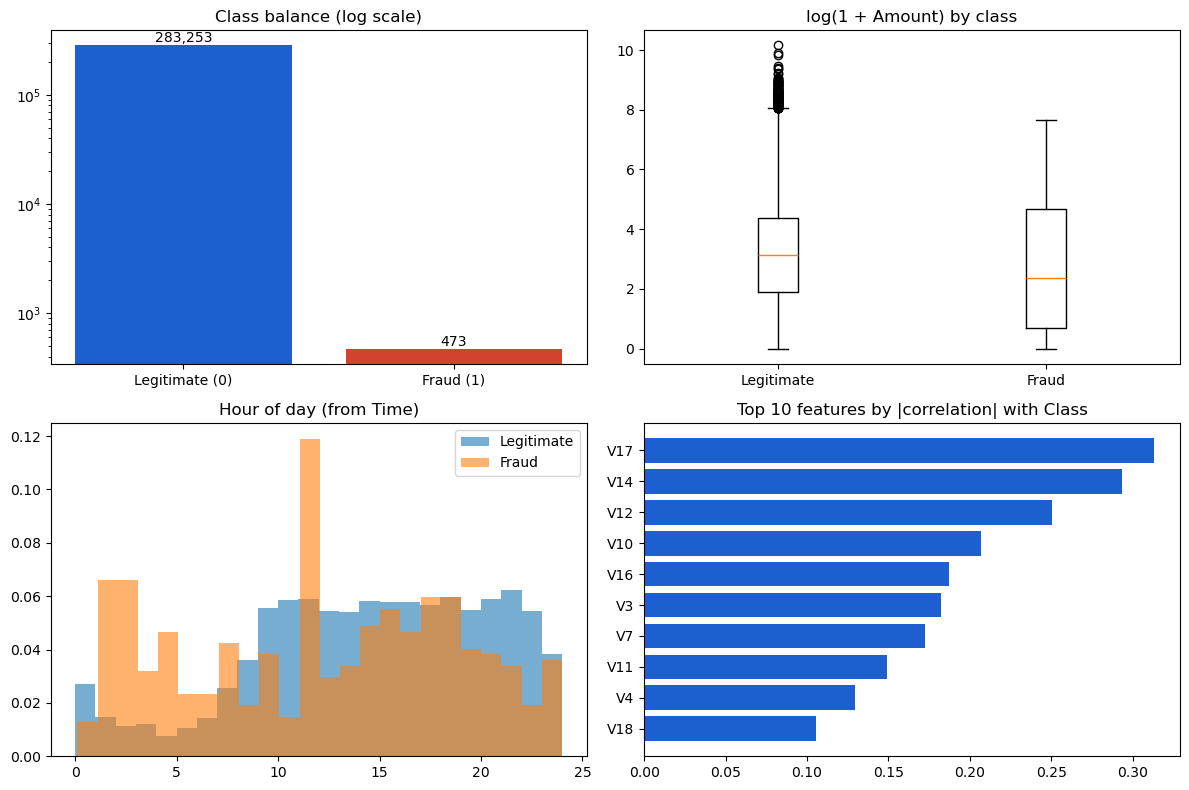

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [5]:
legit, fraud = df[df["Class"] == 0], df[df["Class"] == 1]
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. class balance
counts = df["Class"].value_counts().sort_index()
ax[0, 0].bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=["#1d5fd1", "#d1432d"])
ax[0, 0].set_yscale("log")
ax[0, 0].set_title("Class balance (log scale)")
for i, v in enumerate(counts.values):
    ax[0, 0].text(i, v, f"{v:,}", ha="center", va="bottom")

# 2. transaction amount by class
ax[0, 1].boxplot([np.log1p(legit["Amount"]), np.log1p(fraud["Amount"])])
ax[0, 1].set_xticklabels(["Legitimate", "Fraud"])
ax[0, 1].set_title("log(1 + Amount) by class")

# 3. time of day by class
ax[1, 0].hist((legit["Time"] / 3600) % 24, bins=24, alpha=0.6, density=True, label="Legitimate")
ax[1, 0].hist((fraud["Time"] / 3600) % 24, bins=24, alpha=0.6, density=True, label="Fraud")
ax[1, 0].set_title("Hour of day (from Time)")
ax[1, 0].legend()

# 4. features most related to fraud
top = df.corr()["Class"].drop("Class").abs().sort_values(ascending=False).head(10)
ax[1, 1].barh(top.index[::-1], top.values[::-1], color="#1d5fd1")
ax[1, 1].set_title("Top 10 features by |correlation| with Class")

plt.tight_layout()
plt.show()

df.groupby("Class")["Amount"].describe().round(2)

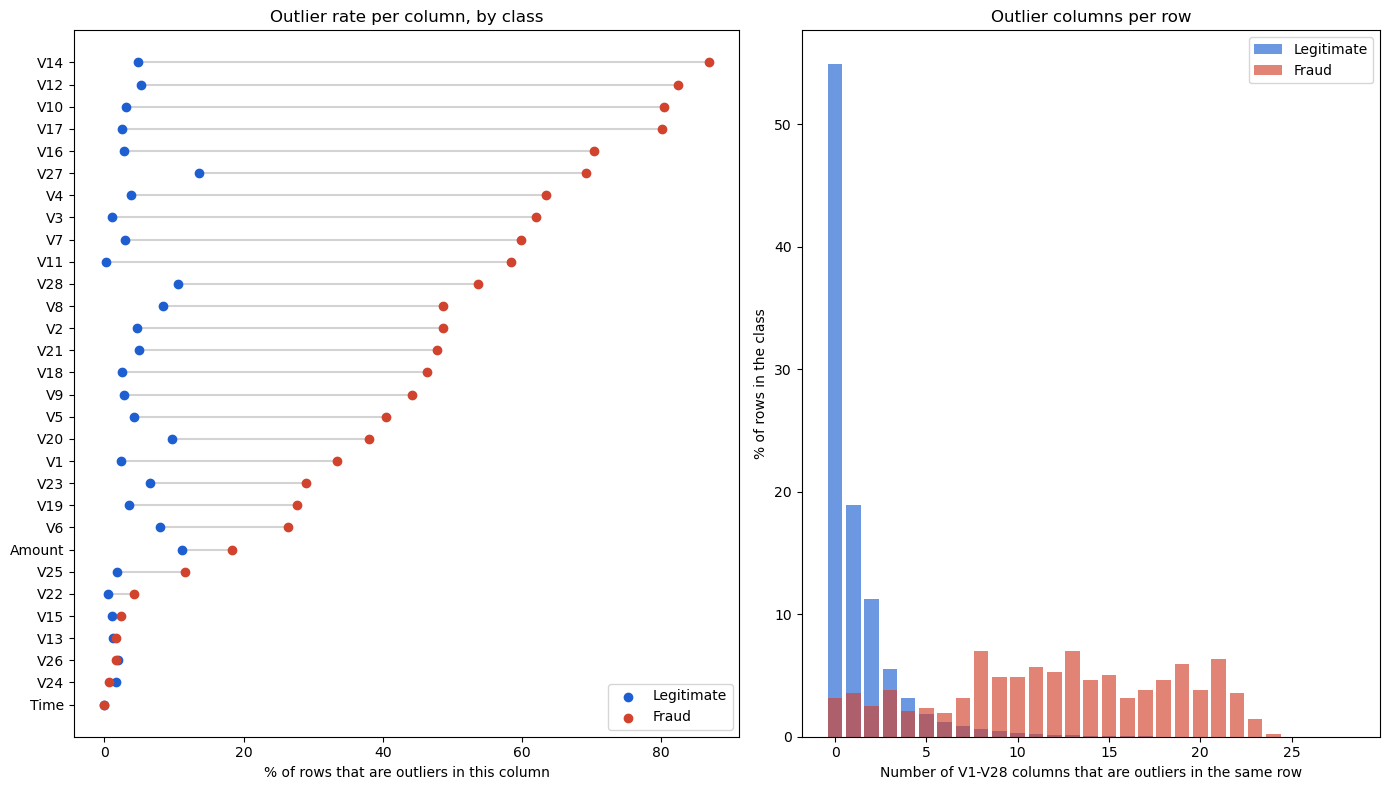

Rows that are outliers in at least one V column: fraud 96.8% | legitimate 45.1%
Average V columns flagged per row:               fraud 12.2 | legitimate 1.2
Amount outliers:                                 fraud 18.4% | legitimate 11.2%


In [19]:
# Are fraud rows "unusual"? Count how often each column is an IQR outlier, split by class.
# (Descriptive EDA only: nothing here feeds a model, so there is no leakage.)
feature_cols = [c for c in df.columns if c != "Class"]
q1, q3 = df[feature_cols].quantile(0.25), df[feature_cols].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[feature_cols] < q1 - 1.5 * iqr) | (df[feature_cols] > q3 + 1.5 * iqr)

is_fraud = df["Class"] == 1
rate = pd.DataFrame({
    "Legitimate": is_outlier[~is_fraud].mean() * 100,
    "Fraud": is_outlier[is_fraud].mean() * 100,
}).sort_values("Fraud")

v_cols = [c for c in feature_cols if c.startswith("V")]
n_flagged = is_outlier[v_cols].sum(axis=1)          # how many of V1-V28 are outliers in each row

fig, ax = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.15, 1]})

# Left: per-column outlier rate, legitimate vs fraud
y = np.arange(len(rate))
ax[0].hlines(y, rate["Legitimate"], rate["Fraud"], color="lightgrey", zorder=1)
ax[0].scatter(rate["Legitimate"], y, color="#1d5fd1", label="Legitimate", zorder=2)
ax[0].scatter(rate["Fraud"], y, color="#d1432d", label="Fraud", zorder=2)
ax[0].set_yticks(y)
ax[0].set_yticklabels(rate.index)
ax[0].set_xlabel("% of rows that are outliers in this column")
ax[0].set_title("Outlier rate per column, by class")
ax[0].legend(loc="lower right")

# Right: how many of the 28 V columns are outliers in the same row
bins = np.arange(0, len(v_cols) + 2)
for label, mask, colour in [("Legitimate", ~is_fraud, "#1d5fd1"), ("Fraud", is_fraud, "#d1432d")]:
    share = np.bincount(n_flagged[mask], minlength=len(v_cols) + 1) / mask.sum() * 100
    ax[1].bar(bins[:-1], share, width=0.8, alpha=0.65, color=colour, label=label)
ax[1].set_xlabel("Number of V1-V28 columns that are outliers in the same row")
ax[1].set_ylabel("% of rows in the class")
ax[1].set_title("Outlier columns per row")
ax[1].legend()

plt.tight_layout()
plt.show()

print(f"Rows that are outliers in at least one V column: fraud {(n_flagged[is_fraud] > 0).mean():.1%} | legitimate {(n_flagged[~is_fraud] > 0).mean():.1%}")
print(f"Average V columns flagged per row:               fraud {n_flagged[is_fraud].mean():.1f} | legitimate {n_flagged[~is_fraud].mean():.1f}")
print(f"Amount outliers:                                 fraud {is_outlier.loc[is_fraud, 'Amount'].mean():.1%} | legitimate {is_outlier.loc[~is_fraud, 'Amount'].mean():.1%}")

**EDA notes**
- **Extreme imbalance.** After removing 1,081 duplicate rows, only 473 of 283,726 transactions (about 0.17%) are fraud. This is the central fact of the project: imbalance can make a model look excellent while catching almost no fraud, which is why accuracy is dropped and SMOTE is used.
- Amount is heavily right-skewed, so it is plotted on a log scale. Most transactions are small. Fraud and legitimate amounts overlap a lot, so Amount on its own does not separate the classes well. Using one IQR cut-off for all transactions, 18.4% of fraud rows and 11.2% of legitimate rows count as unusually large.
- **Fraud is unusual in the `V` columns, not in `Amount`.** About 97% of fraud rows are outliers in at least one of `V1` to `V28`, against about 45% of legitimate rows. A typical fraud row is extreme in about 12 of the 28 columns, while a legitimate row is extreme in about 1. The features most correlated with `Class` are `V17`, `V14`, `V12` and `V10`.
- **Outliers are deliberately kept.** In Project 1 extreme values were capped. Here they are left alone because the fraud rows are themselves the unusual ones. Capping would erase the pattern that identifies fraud, and with only 473 fraud cases every one matters.
- **Timing.** The hour-of-day panel in the plot above suggests that fraud is spread differently through the day than legitimate transactions. Legitimate transactions are concentrated in the daytime (roughly hours 9 to 22), while a larger share of fraud falls in the early hours (roughly 1 to 5), with a spike around hours 11 to 12. With only 473 fraud cases this is only suggestive. Time counts seconds from the first transaction, so “hour of day” is approximate.
- **`V1` to `V28` are anonymised components** of the original features, so they cannot be interpreted individually. `Time` and `Amount` are not on the same scale as them, which matters for Logistic Regression.

## Module 2: Split first, then everything else
### 2.1 Stratified train/test split
The split happens **before** SMOTE or any scaling, which is the brief's golden rule. `stratify=y` keeps the fraud share identical in both parts, so the test set cannot end up with almost no fraud.

In [6]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {X_train.shape[0]:,} rows | fraud share {y_train.mean():.4%} | fraud cases {int(y_train.sum())}")
print(f"Test:  {X_test.shape[0]:,} rows | fraud share {y_test.mean():.4%} | fraud cases {int(y_test.sum())}")

Train: 226,980 rows | fraud share 0.1665% | fraud cases 378
Test:  56,746 rows | fraud share 0.1674% | fraud cases 95


### 2.2 The accuracy illusion (baseline)
A model that labels **every** transaction "legitimate" needs no learning at all. Its score shows why accuracy is the wrong yardstick here.

In [7]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
b_pred = baseline.predict(X_test)
b_proba = baseline.predict_proba(X_test)[:, 1]

print(f"Accuracy:            {accuracy_score(y_test, b_pred):.4%}")
print(f"Recall (fraud caught): {recall_score(y_test, b_pred):.2%}")
print(f"Precision:           {precision_score(y_test, b_pred, zero_division=0):.2%}")
print(f"ROC-AUC:             {roc_auc_score(y_test, b_proba):.2f}   (0.50 = coin flip)")

Accuracy:            99.8326%
Recall (fraud caught): 0.00%
Precision:           0.00%
ROC-AUC:             0.50   (0.50 = coin flip)


Near-perfect accuracy, zero fraud caught. Every model from here on is judged on **Precision, Recall, F1 and ROC-AUC** instead.

### 2.3 What SMOTE does (demonstration on the training set only)
SMOTE creates new, slightly different fraud examples by interpolating between real fraud cases and their nearest fraud neighbours, so the model sees a balanced training set. It is applied here **only to the training data**, and the test set is left exactly as it is. This cell is just a demonstration. The real SMOTE step happens inside the pipelines in Module 3, where it is re-run separately for every cross-validation fold.

In [8]:
X_demo, y_demo = SMOTE(random_state=RANDOM_SEED).fit_resample(X_train, y_train)

print("Training set before SMOTE:", dict(Counter(y_train)))
print("Training set after SMOTE: ", dict(Counter(y_demo)))
print("Test set (untouched):     ", dict(Counter(y_test)))
del X_demo, y_demo

Training set before SMOTE: {0: 226602, 1: 378}
Training set after SMOTE:  {0: 226602, 1: 226602}
Test set (untouched):      {0: 56651, 1: 95}


## Module 3: Leak-free pipelines and tuning
### 3.1 The two pipelines
Both use `imblearn.pipeline.Pipeline`, so each step is fitted only on the training portion of whatever data it receives.

| Model | Steps | Why |
|---|---|---|
| Logistic Regression | `StandardScaler` → `SMOTE` → classifier | It is sensitive to scale (`Amount` and `Time` are on much larger scales than `V1` to `V28`) |
| Random Forest | `SMOTE` → classifier | Trees split on thresholds, so they do not need scaling |

The scaler sits **inside** the pipeline. If it were applied to all data first, the test set's mean and variance would leak into training.

In [9]:
lr_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_SEED)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
])

rf_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_SEED)),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)),
])

### 3.2 Hyperparameter grids
Hyperparameters are settings chosen *before* training. `GridSearchCV` tries every combination, using 5-fold stratified cross-validation, and each fold gets its own fresh SMOTE and scaler fitted on that fold's training part only.

| Parameter | Meaning |
|---|---|
| `smote__k_neighbors` | How many nearby fraud cases SMOTE looks at when creating a new one |
| `classifier__C` | Inverse regularisation strength for Logistic Regression (small = strong penalty) |
| `classifier__max_depth` | How deep each tree in the Random Forest may grow |

The search is scored on ROC-AUC, with Recall and F1 also recorded. Accuracy is not used.

In [10]:
lr_grid = {
    "smote__k_neighbors": [3, 5, 7],
    "classifier__C": [0.01, 0.1, 1.0],
}
rf_grid = {
    "smote__k_neighbors": [3, 5],
    "classifier__max_depth": [10, 20],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"}

# A stratified sample of the TRAINING set is used for the search (assumption A3); the test set is not touched.
if TUNE_SAMPLE_SIZE and len(X_train) > TUNE_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNE_SAMPLE_SIZE, stratify=y_train, random_state=RANDOM_SEED
    )
else:
    X_tune, y_tune = X_train, y_train
print(f"Rows used for tuning: {len(X_tune):,} | fraud cases: {int(y_tune.sum())}")

Rows used for tuning: 100,000 | fraud cases: 167


In [11]:
def tune(name, pipe, grid, n_jobs):
    start = time.time()
    search = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit="roc_auc", n_jobs=n_jobs)
    search.fit(X_tune, y_tune)
    print(f"{name}: best params {search.best_params_}")
    print(f"  best CV ROC-AUC {search.best_score_:.4f} | search took {time.time() - start:.0f}s")
    res = pd.DataFrame(search.cv_results_)
    cols = ["params", "mean_test_roc_auc", "mean_test_recall", "mean_test_f1"]
    display(res.sort_values("mean_test_roc_auc", ascending=False)[cols].head(5).round(4))
    return search

lr_search = tune("Logistic Regression", lr_pipe, lr_grid, n_jobs=-1)

Logistic Regression: best params {'classifier__C': 0.01, 'smote__k_neighbors': 5}
  best CV ROC-AUC 0.9798 | search took 17s


,params,mean_test_roc_auc,mean_test_recall,mean_test_f1
1,"{'classifier__C': 0.01, 'smote__k_neighbors': 5}",0.9798,0.8979,0.1008
0,"{'classifier__C': 0.01, 'smote__k_neighbors': 3}",0.9797,0.9100,0.1003
2,"{'classifier__C': 0.01, 'smote__k_neighbors': 7}",0.9796,0.9098,0.1014
4,"{'classifier__C': 0.1, 'smote__k_neighbors': 5}",0.9780,0.8979,0.1006
3,"{'classifier__C': 0.1, 'smote__k_neighbors': 3}",0.9780,0.9098,0.1000


In [12]:
rf_search = tune("Random Forest", rf_pipe, rf_grid, n_jobs=1)   # the forest itself already uses all CPU cores

Random Forest: best params {'classifier__max_depth': 10, 'smote__k_neighbors': 5}
  best CV ROC-AUC 0.9833 | search took 583s


,params,mean_test_roc_auc,mean_test_recall,mean_test_f1
1,"{'classifier__max_depth': 10, 'smote__k_neighb...",0.9833,0.8082,0.7702
0,"{'classifier__max_depth': 10, 'smote__k_neighb...",0.9786,0.8262,0.8021
2,"{'classifier__max_depth': 20, 'smote__k_neighb...",0.9742,0.7963,0.8192
3,"{'classifier__max_depth': 20, 'smote__k_neighb...",0.9715,0.7963,0.8168


### 3.3 Retrain the best settings on the full training set
Each model is rebuilt with its winning hyperparameters and fitted on the **entire** training set. The test set is still untouched.

In [13]:
final_models = {}
for name, search, base in [("Logistic Regression", lr_search, lr_pipe),
                           ("Random Forest", rf_search, rf_pipe)]:
    start = time.time()
    model = clone(base).set_params(**search.best_params_)
    model.fit(X_train, y_train)
    final_models[name] = model
    print(f"{name}: trained on {len(X_train):,} rows in {time.time() - start:.0f}s")

Logistic Regression: trained on 226,980 rows in 1s
Random Forest: trained on 226,980 rows in 64s


## Module 4: Final evaluation on the untouched test set
This is the first and only time the models see the test set.

- **Precision** = TP ÷ (TP + FP): when the model flags fraud, how often is it right?
- **Recall** = TP ÷ (TP + FN): of all real fraud, how much was caught?
- **F1**: a single score balancing the two.
- **ROC-AUC**: how well the model separates fraud from legitimate overall (0.5 = coin flip, 1.0 = perfect).
- **Average precision** (area under the precision-recall curve) is also shown because it is especially informative when positives are rare.

In [14]:
rows, probas, matrices = [], {}, {}
for name, model in final_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    probas[name] = proba
    matrices[name] = confusion_matrix(y_test, pred)
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Avg precision": average_precision_score(y_test, proba),
    })

rows.append({"Model": "Baseline (always 'legitimate')", "Precision": 0.0, "Recall": 0.0, "F1": 0.0,
             "ROC-AUC": 0.5, "Avg precision": float(y_test.mean())})
results = pd.DataFrame(rows).set_index("Model")

os.makedirs("outputs", exist_ok=True)
results.round(4).to_csv("outputs/model_comparison.csv")
results.round(4)

,Precision,Recall,F1,ROC-AUC,Avg precision
Model,,,,,
Logistic Regression,0.0534,0.8737,0.1007,0.9623,0.6582
Random Forest,0.6016,0.8105,0.6906,0.9729,0.7716
Baseline (always 'legitimate'),0.0000,0.0000,0.0000,0.5000,0.0017


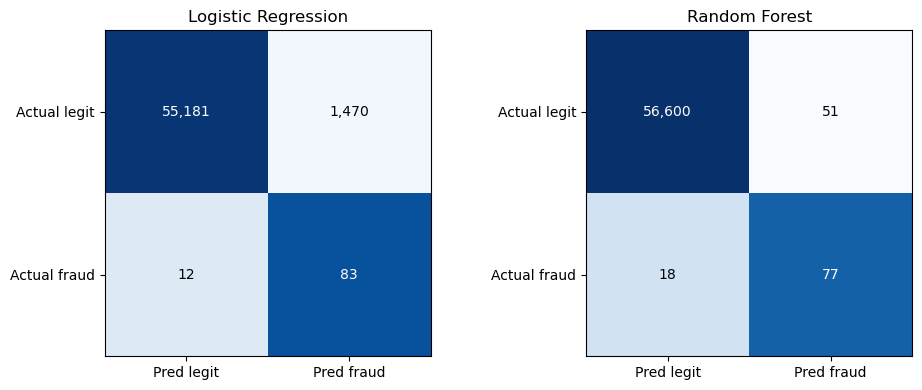

Logistic Regression: caught 83 frauds, missed 12, falsely flagged 1470 legitimate transactions
Random Forest: caught 77 frauds, missed 18, falsely flagged 51 legitimate transactions


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cm) in zip(axes, matrices.items()):
    share = cm / cm.sum(axis=1, keepdims=True)      # shade each row by its own proportion so the fraud row is visible
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred legit", "Pred fraud"]); ax.set_yticklabels(["Actual legit", "Actual fraud"])
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if share[i, j] > 0.5 else "black")
plt.tight_layout()
plt.show()

for name, cm in matrices.items():
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}: caught {tp} frauds, missed {fn}, falsely flagged {fp} legitimate transactions")

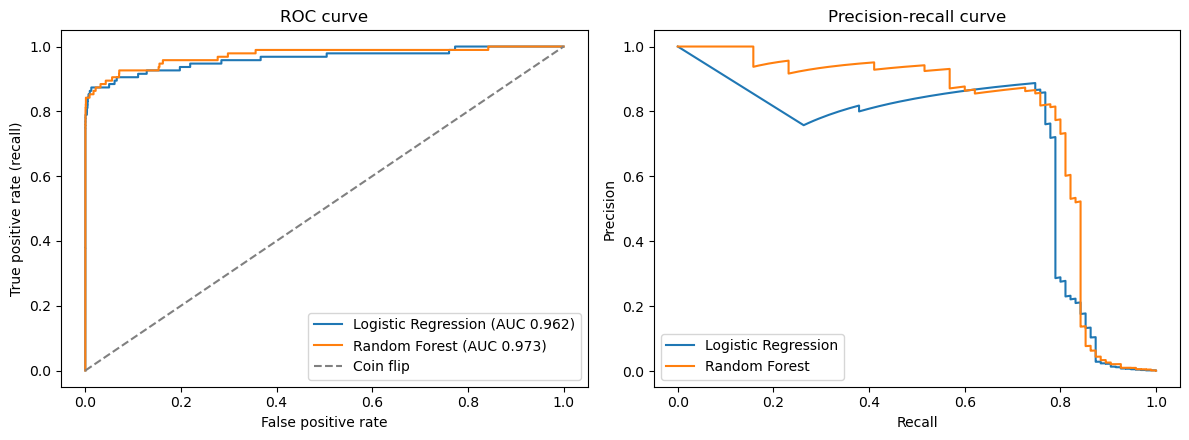

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
    p, r, _ = precision_recall_curve(y_test, proba)
    ax[1].plot(r, p, label=name)
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Coin flip")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curve"); ax[0].legend()
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curve"); ax[1].legend()
plt.tight_layout()
plt.show()

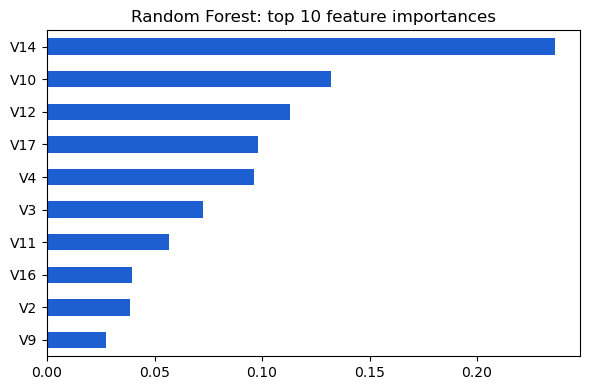

In [17]:
# What the Random Forest relied on most
rf_model = final_models["Random Forest"].named_steps["classifier"]
imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
imp[::-1].plot.barh(color="#1d5fd1", figsize=(6, 4), title="Random Forest: top 10 feature importances")
plt.tight_layout()
plt.show()

,precision,recall,f1
threshold,,,
0.1,0.049,0.921,0.094
0.2,0.145,0.889,0.249
0.3,0.275,0.873,0.419
0.4,0.451,0.857,0.591
0.5,0.611,0.844,0.709
0.6,0.742,0.839,0.788
0.7,0.811,0.817,0.814
0.8,0.855,0.812,0.833
0.9,0.867,0.762,0.811


Training-data precision at 0.5: 0.611
Chosen threshold: 0.50  (recall 0.844, precision 0.611)
For reference, the F1-maximising threshold is 0.81


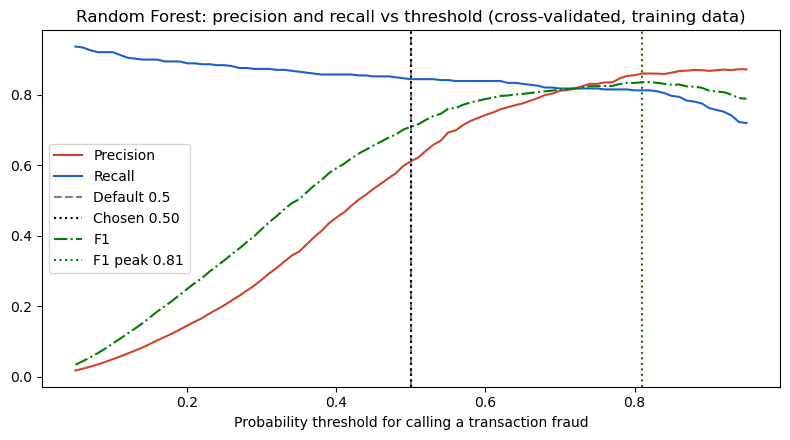

,Precision,Recall,F1,Caught,Missed,False alarms
Threshold,,,,,,
Default (0.50),0.6016,0.8105,0.6906,77,18,51
Tuned (0.50),0.6016,0.8105,0.6906,77,18,51


In [22]:
from sklearn.model_selection import cross_val_predict

# 1. Out-of-fold fraud probabilities on the TRAINING set only.
#    Each training row is scored by a model that never saw it, so the test set is not involved.
rf_final = final_models["Random Forest"]
oof_proba = cross_val_predict(clone(rf_final), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=1)[:, 1]

# 2. Precision and recall at many thresholds (training data only)
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, oof_proba >= t, zero_division=0) for t in grid],
    "recall":    [recall_score(y_train, oof_proba >= t) for t in grid],
}).set_index("threshold")
sweep["f1"] = 2 * sweep["precision"] * sweep["recall"] / (sweep["precision"] + sweep["recall"]).replace(0, np.nan)
display(sweep.loc[np.round(np.arange(0.1, 0.91, 0.1), 2)].round(3))

# 3. Selection rule, fixed BEFORE looking at the test set:
#    highest recall among thresholds whose precision is at least the precision at 0.5.
p_default = sweep.loc[0.5, "precision"]
eligible = sweep[sweep["precision"] >= p_default]
best_t = float(eligible["recall"].idxmax())
print(f"Training-data precision at 0.5: {p_default:.3f}")
print(f"Chosen threshold: {best_t:.2f}  (recall {sweep.loc[best_t, 'recall']:.3f}, precision {sweep.loc[best_t, 'precision']:.3f})")
print(f"For reference, the F1-maximising threshold is {sweep['f1'].idxmax():.2f}")

# 4. Precision and recall against the threshold
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep.index, sweep["precision"], label="Precision", color="#d1432d")
ax.plot(sweep.index, sweep["recall"], label="Recall", color="#1d5fd1")
ax.axvline(0.5, color="grey", linestyle="--", label="Default 0.5")
ax.axvline(best_t, color="black", linestyle=":", label=f"Chosen {best_t:.2f}")
ax.set_xlabel("Probability threshold for calling a transaction fraud")
ax.set_title("Random Forest: precision and recall vs threshold (cross-validated, training data)")
ax.plot(sweep.index, sweep["f1"], label="F1", color="green", linestyle="-.")
ax.axvline(sweep["f1"].idxmax(), color="green", linestyle=":", label=f"F1 peak {sweep['f1'].idxmax():.2f}")
ax.legend()
plt.tight_layout()
plt.show()

# 5. Apply the chosen threshold to the test set ONCE
test_proba = probas["Random Forest"]
rows = []
for label, t in [("Default (0.50)", 0.5), (f"Tuned ({best_t:.2f})", best_t)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": label, "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "Caught": tp, "Missed": fn, "False alarms": fp})
pd.DataFrame(rows).set_index("Threshold").round(4)

In [21]:
# Optional: also report the threshold that maximised F1 on the training data (chosen without the test set)
f1_t = float(sweep["f1"].idxmax())
rows = []
for label, t in [("Default (0.50)", 0.5), (f"F1-optimal ({f1_t:.2f})", f1_t)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": label, "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "Caught": tp, "Missed": fn, "False alarms": fp})
pd.DataFrame(rows).set_index("Threshold").round(4)

,Precision,Recall,F1,Caught,Missed,False alarms
Threshold,,,,,,
Default (0.50),0.6016,0.8105,0.6906,77,18,51
F1-optimal (0.81),0.8734,0.7263,0.7931,69,26,10


**Reading the results**
- Precision and recall pull against each other. Catching more fraud (higher recall) usually means flagging more legitimate transactions by mistake (lower precision). The models above use the default 0.5 cut-off; a real system would move that cut-off based on the cost of a missed fraud versus a blocked customer.
- SMOTE improves recall mostly by letting the model see a balanced training set. Because the test set stays imbalanced, even a small false-positive rate produces many false alarms, so precision is usually the harder number.
- **Possible extension (not done here):** SMOTE finds neighbours by distance, and `Time` and `Amount` are on a much larger scale than `V1` to `V28`. Scaling before SMOTE in the Random Forest pipeline as well could change which neighbours it picks. The brief's Random Forest pipeline has no scaler, so this notebook follows the brief.

## Decision log
The table below is computed from this run's results.

In [18]:
best_name = results.drop(index="Baseline (always 'legitimate')")["ROC-AUC"].idxmax()
decision_log = pd.DataFrame([
    ["Data quality", f"{int(raw_data.isnull().sum().sum())} missing values; {n_dupes} duplicate rows",
     "Dropped exact duplicates before splitting (assumption A2)", f"{len(df):,} rows remain"],
    ["Class imbalance", f"Fraud is {df['Class'].mean():.3%} of rows ({int(df['Class'].sum())} cases)",
     "Accuracy rejected; Precision, Recall, F1 and ROC-AUC used", f"Baseline accuracy {accuracy_score(y_test, b_pred):.2%} with 0% recall"],
    ["Outliers", "Extreme Amount values present", "Kept: unusual transactions can be the fraud signal", "0 rows altered"],
    ["Split", "80/20, stratified on Class", "Done before SMOTE and scaling to avoid leakage", f"Test fraud cases: {int(y_test.sum())}"],
    ["Rebalancing", "SMOTE (interpolates new fraud examples)", "Inside the imblearn Pipeline, fitted on training folds only", "Test set never resampled"],
    ["Scaling", "Amount/Time on a different scale to V1-V28", "StandardScaler inside the Logistic Regression pipeline only", "Random Forest unscaled"],
    ["Tuning", "5-fold stratified GridSearchCV, scored on ROC-AUC", f"Search on {len(X_tune):,}-row training sample (assumption A3)", f"LR {lr_search.best_params_}; RF {rf_search.best_params_}"],
    ["Best model", f"{best_name} had the highest test ROC-AUC", "Evaluated once on the untouched test set", f"ROC-AUC {results.loc[best_name, 'ROC-AUC']:.3f}"],
], columns=["Step", "Finding", "Decision", "Impact"])
decision_log

,Step,Finding,Decision,Impact
0,Data quality,0 missing values; 1081 duplicate rows,Dropped exact duplicates before splitting (ass...,"283,726 rows remain"
1,Class imbalance,Fraud is 0.167% of rows (473 cases),"Accuracy rejected; Precision, Recall, F1 and R...",Baseline accuracy 99.83% with 0% recall
2,Outliers,Extreme Amount values present,Kept: unusual transactions can be the fraud si...,0 rows altered
3,Split,"80/20, stratified on Class",Done before SMOTE and scaling to avoid leakage,Test fraud cases: 95
4,Rebalancing,SMOTE (interpolates new fraud examples),"Inside the imblearn Pipeline, fitted on traini...",Test set never resampled
5,Scaling,Amount/Time on a different scale to V1-V28,StandardScaler inside the Logistic Regression ...,Random Forest unscaled
6,Tuning,"5-fold stratified GridSearchCV, scored on ROC-AUC","Search on 100,000-row training sample (assumpt...","LR {'classifier__C': 0.01, 'smote__k_neighbors..."
7,Best model,Random Forest had the highest test ROC-AUC,Evaluated once on the untouched test set,ROC-AUC 0.973


**My conclusions:**
- The Random Forest performed better overall. It had a higher ROC-AUC (0.973 vs 0.962) and much higher precision (0.60 vs 0.05) and F1 (0.69 vs 0.10). Logistic Regression had slightly higher recall (0.87 vs 0.81), but it achieved this by flagging far too many legitimate transactions (roughly 1,470 false alarms, against 51 for the Random Forest). For catching fraud in practice, the Random Forest is the more useful model, because most of its alerts are real fraud and an investigator's time is not wasted.
- Logistic Regression leans towards recall: it catches 83 of the 95 test frauds but at the cost of very low precision, so about 95% of its alerts are false. The Random Forest is more balanced: it catches 77 of 95 and falsely flags only 51 legitimate transactions. Lowering the Random Forest’s threshold below 0.5 did not help: at a threshold of 0.4, recall rose by only 0.013 (from 0.844 to 0.857), while precision fell by 0.160 (from 0.611 to 0.451). Since this small gain in recall came at a large cost in precision, I kept the default threshold of 0.50.
- A model that labels every transaction "legitimate" scored 99.83% accuracy while catching 0% of fraud, which shows accuracy is misleading on imbalanced data. SMOTE must sit inside the pipeline, after the train/test split, so that synthetic fraud examples are created only from training data in each cross-validation fold. If SMOTE ran before the split, synthetic points built from test rows would leak into training and inflate the scores.